In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.DataFrame({'Age': [24,32,41,29], 'Salary':[1,120,90,80]})

In [4]:
df

,Age,Salary
0,24,1
1,32,120
2,41,90
3,29,80


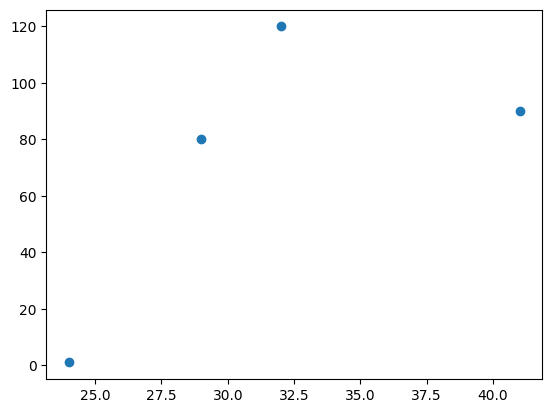

In [5]:
plt.scatter(df['Age'], df['Salary'])

In [6]:
df['Salary'].mean()

72.75

In [7]:
df['p0'] = df['Salary'].mean()

In [8]:
df

,Age,Salary,p0
0,24,1,72.75
1,32,120,72.75
2,41,90,72.75
3,29,80,72.75


In [9]:
df['res0'] = df['Salary'] - df['p0']

In [10]:
df

,Age,Salary,p0,res0
0,24,1,72.75,-71.75
1,32,120,72.75,47.25
2,41,90,72.75,17.25
3,29,80,72.75,7.25


In [11]:
!pip install xgboost

In [12]:
df = pd.read_csv('BostonHousing.csv')

In [13]:
df

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [16]:
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [32]:
xgb=XGBRegressor(eta=0.3,gamma=50,reg_lambda=10)
gb=GradientBoostingRegressor()
rf=RandomForestRegressor()

In [33]:
from sklearn.model_selection import cross_val_score

In [34]:
X = df.iloc[:,0:-1]

In [35]:
y = df.iloc[:,-1]

In [36]:
X

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48


In [37]:
y

0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: medv, Length: 506, dtype: float64

In [41]:
import time

In [42]:
start = time.time()
print("XG Boost : ", np.mean(cross_val_score(xgb,X,y,cv=10))*100)
print("The time taken is : ", time.time()-start)

XG Boost :  44.526570671868356
The time taken is :  1.1053407192230225


In [43]:
start = time.time()
print("Gradient Boost : ", np.mean(cross_val_score(gb,X,y,cv=10))*100)
print("The time taken is : ", time.time()-start)

Gradient Boost :  44.72765701007192
The time taken is :  4.375270843505859


In [44]:
start = time.time()
print("Random Forest: ", np.mean(cross_val_score(rf,X,y,cv=10))*100)
print("The time taken is : ", time.time()-start)

Random Forest:  49.605891614351215
The time taken is :  10.631778955459595
